# 07 · Resumo Executivo
**Previsão de demanda — Corporación Favorita (Equador)**

Este notebook reúne, em uma visão de gestão, os resultados de todo o projeto:
o problema, a precisão do modelo, a previsão das próximas quinzenas, os principais
insights e o plano de ação recomendado.

## ⏱️ Resumo em 30 segundos

| Indicador | Resultado |
|---|---|
| 🎯 **Objetivo** | Prever quantas unidades de cada produto cada uma das **54 lojas** vai vender nas **duas quinzenas seguintes** |
| 🤖 **Solução** | 30 modelos de *machine learning* (LightGBM), um para cada dia à frente, com ajuste final do volume previsto |
| 📉 **Ganho sobre métodos simples** | **9% menos erro** do que repetir a média de vendas das últimas semanas |
| ⚖️ **Correção da previsão** | O modelo original previa **~21% abaixo** do que realmente vendeu; após o ajuste, a diferença caiu para **~3%** |
| 🎯 **Precisão para compras** | Ao planejar a compra de uma **família de produtos** para a quinzena, o erro é de **~6%** |
| 📦 **Previsão 16–30/ago** | **11,9 milhões** de unidades (4,6% abaixo do ritmo das últimas semanas) |
| 📦 **Previsão 31/ago–14/set** | **12,8 milhões** de unidades (2,3% acima, puxada pelo pagamento de salários do início de setembro) |


> **📖 Conceitos-chave**
>
> - **Família de produtos:** agrupamento de itens da mesma categoria, como **mercearia**
>   (arroz, óleo, enlatados), **bebidas**, **hortifrúti**, **limpeza** e **laticínios**. A rede
>   tem **33 famílias** e ~4 mil itens. É o nível em que normalmente se negocia e se compra
>   dos fornecedores.
> - **Ruptura:** quando o produto **falta na prateleira** e o cliente não consegue comprar —
>   a venda é perdida e o cliente pode ir ao concorrente.
> - **Ruptura sistemática:** quando a falta **não é um acidente isolado, mas um padrão que
>   se repete**. Sem o ajuste, a previsão ficava ~21% abaixo da demanda real em quase todos
>   os dias e produtos — se usada para comprar, a rede compraria **sempre de menos**.
> - **Ajuste (calibração):** correção aplicada à previsão para que o **volume total previsto
>   bata com o volume realmente vendido**, sem perder os padrões aprendidos pelo modelo.
> - **Erro de ~6%:** em média, a quantidade prevista para a quinzena de uma família de
>   produtos fica ~6% acima ou abaixo do que de fato vende.

**Principal mensagem:** a demanda da rede é **previsível no nível em que se compra**
(família de produtos × quinzena). Os padrões de **fim de semana**, **pagamento de salários**
e **promoções** devem guiar as decisões de compra, reposição das lojas e escala de equipe.

## 1. O problema e a solução

**O desafio.** Uma rede de supermercados com **54 lojas** e **~4 mil produtos** precisa
decidir, a cada ciclo, **quanto comprar e distribuir** para cada loja. Comprar de menos
gera **ruptura** (venda perdida, cliente insatisfeito); comprar demais gera **estoque
parado** e, nos perecíveis, **perda**.

**Os dados.** Histórico diário de vendas por loja × item (2013–2017, ~125 milhões de
registros), com promoções, feriados, lojas e cadastro de produtos. O projeto usou
**2017 completo** (23,8 milhões de registros) para a modelagem.

**A solução.**
| Etapa | O que foi feito |
|---|---|
| Análise exploratória | padrões de tendência, sazonalidade, pagamento, promoções, feriados, lojas e produtos |
| Engenharia de features | 61 variáveis por loja × item: histórico recente, padrão semanal, intermitência, promoções, calendário |
| Modelagem | **30 modelos LightGBM** — um para cada dia à frente (*previsão direta*) |
| Validação | teste "às cegas" em 17/jul–15/ago/2017, contra modelos simples (*baselines*) |
| Calibração | correção do viés para que o volume previsto bata com o realizado |
| Previsão final | **16/ago a 14/set/2017**, em duas quinzenas, por loja × item × dia |

## 2. Quão precisa é a previsão?
Medimos o erro do modelo final (LightGBM calibrado) no período de validação, em
**diferentes níveis de agregação** — do item na gôndola até a rede inteira. Cada nível
corresponde a uma decisão diferente da empresa.

**WAPE** = % do volume previsto errado (quanto menor, melhor) · **Viés** = previsão
acima (+) ou abaixo (−) do realizado.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROC = Path("../data/processed")
FIG = Path("../reports/figures")

pv = pd.read_parquet(PROC / "painel_validacao.parquet")      # validação (real × previsto)
pf = pd.read_parquet(PROC / "previsao_futura.parquet")       # previsão oficial
pv["quinzena"] = np.where(pv["h"] <= 15, "1ª quinzena", "2ª quinzena")

def wape(real, prev):
    return float(np.abs(prev - real).sum() / real.sum())

niveis = {
    "Loja × item (reposição da gôndola)": ["store_nbr", "item_nbr"],
    "Loja × família (pedido da loja)": ["store_nbr", "family"],
    "Família na rede (compra do fornecedor)": ["family"],
    "Rede inteira (orçamento)": [],
}

linhas = []
for nome, chaves in niveis.items():
    tot = pv.groupby(chaves + ["quinzena"], observed=True)[["real", "previsto"]].sum()
    for q, g in tot.groupby(level="quinzena"):
        linhas.append({"Nível": nome, "Quinzena": q,
                       "WAPE": wape(g["real"], g["previsto"]),
                       "Viés": g["previsto"].sum() / g["real"].sum() - 1})
erros = pd.DataFrame(linhas)

tabela = erros.pivot(index="Nível", columns="Quinzena", values=["WAPE", "Viés"]).reindex(list(niveis))
tabela.style.format("{:.1%}")

### 💡 A precisão depende do nível da decisão

| Nível | Decisão que apoia | WAPE 1ª quinz. | WAPE 2ª quinz. |
|---|---|---|---|
| Loja × item | reposição da gôndola | 27,2% | 33,2% |
| Loja × família | pedido de cada loja | **8,9%** | **11,6%** |
| Família na rede | compra do fornecedor | **6,5%** | **6,2%** |
| Rede inteira | orçamento e capacidade | **5,2%** | **0,0%** |

1. **Quanto mais agregada a decisão, mais precisa a previsão:** os erros individuais de
   cada item, para cima e para baixo, se compensam. Do item na gôndola (~30%) para a
   compra por família (~6%), **o erro cai cerca de 5 vezes**.
2. **Para compras com fornecedores e planejamento financeiro, a previsão é muito
   confiável** (erro de 5–12%).
3. **Na gôndola (loja × item), o erro de ~30% é esperado:** um item específico numa loja
   específica vende poucas unidades por dia, de forma irregular. Aqui a previsão deve
   ser combinada com **estoque de segurança** e reposição frequente.
4. **Viés de −5,2% na 1ª quinzena** (a 2ª metade de julho vendeu acima do padrão de junho)
   e **zero na 2ª**: o volume total ficou bem calibrado.

**Implicação:** planejar **de cima para baixo** — volume por família e loja guiado pela
previsão; distribuição item a item com margem de segurança proporcional ao erro.

## 3. Visão geral: validação e previsão das próximas quinzenas
À esquerda, o teste "às cegas" (o modelo não conhecia esses dados); à direita, a
previsão oficial para os 30 dias seguintes ao fim do histórico.

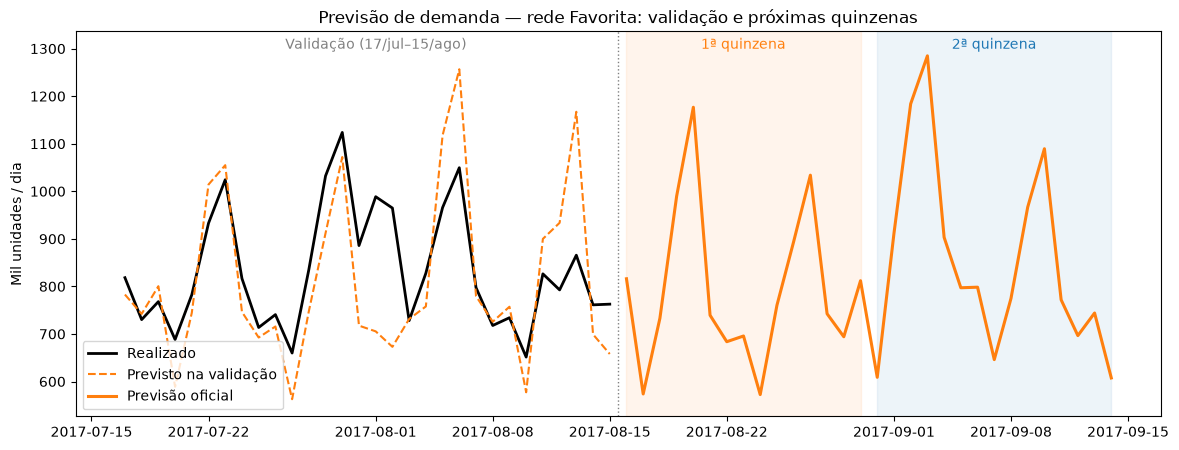

Previsão 1ª quinzena (16/08–30/08): 11.92 milhões de unidades
Previsão 2ª quinzena (31/08–14/09): 12.78 milhões de unidades


In [2]:
val = pv.groupby("date")[["real", "previsto"]].sum() / 1000
fut = pf.groupby("date")["previsto"].sum() / 1000
inicio_fut = fut.index.min()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(val.index, val["real"], color="black", lw=2, label="Realizado")
ax.plot(val.index, val["previsto"], color="C1", lw=1.5, ls="--", label="Previsto na validação")
ax.plot(fut.index, fut.values, color="C1", lw=2.2, label="Previsão oficial")
ax.axvspan(inicio_fut, inicio_fut + pd.Timedelta(days=14), color="C1", alpha=0.08)
ax.axvspan(inicio_fut + pd.Timedelta(days=15), fut.index.max(), color="C0", alpha=0.08)
ax.axvline(inicio_fut - pd.Timedelta(hours=12), color="gray", ls=":", lw=1)

topo = max(val.values.max(), fut.values.max()) * 1.04
ax.set_ylim(top=topo)
ax.text(val.index[len(val) // 2], topo * 0.99, "Validação (17/jul–15/ago)", ha="center", va="top", color="gray")
ax.text(inicio_fut + pd.Timedelta(days=7), topo * 0.99, "1ª quinzena", ha="center", va="top", color="C1")
ax.text(inicio_fut + pd.Timedelta(days=22), topo * 0.99, "2ª quinzena", ha="center", va="top", color="C0")
ax.set(title="Previsão de demanda — rede Favorita: validação e próximas quinzenas",
       ylabel="Mil unidades / dia")
ax.legend(loc="lower left")
plt.savefig(FIG / "07_visao_geral.png", dpi=130, bbox_inches="tight")
plt.show()

# Números-chave da previsão
q1 = pf["h"] <= 15
print(f"Previsão 1ª quinzena ({pf.loc[q1, 'date'].min():%d/%m}–{pf.loc[q1, 'date'].max():%d/%m}): "
      f"{pf.loc[q1, 'previsto'].sum() / 1e6:.2f} milhões de unidades")
print(f"Previsão 2ª quinzena ({pf.loc[~q1, 'date'].min():%d/%m}–{pf.loc[~q1, 'date'].max():%d/%m}): "
      f"{pf.loc[~q1, 'previsto'].sum() / 1e6:.2f} milhões de unidades")

### 💡 Leitura do gráfico
- **Na validação**, a previsão acompanha o nível e o ritmo semanal da demanda real, com dois
  pontos fracos já identificados: subestima o **pico do pagamento** (31/jul–02/ago) e
  superestima os **fins de semana de agosto** — inclusive o prolongado pelo feriado de 11/ago.
- **Na previsão oficial**, o padrão semanal se mantém (picos aos sábados e domingos) e o
  **maior pico do período é o fim de semana de 02–03/set**, logo após o pagamento de setembro.
- A **2ª quinzena** (12,8 mi) supera a **1ª** (11,9 mi) em **+7,2%**, coerente com o efeito
  do início de mês observado na EDA.

## 4. Os 8 principais insights do projeto

**1. A demanda é estável e tem ritmo semanal forte.**
Sábado e domingo concentram **~35% do volume** semanal (índices 121 e 127); quinta-feira é
o dia mais fraco (78). Fora de dezembro (+20–25%), o volume é estável, com crescimento de
~3% ao ano.

**2. O pagamento move o mês.**
Os dias 1–5 vendem **13–28% acima da média**, e a 1ª metade do mês vende ~6% mais que a 2ª.
Itens de "compra do mês" oscilam muito: limpeza varia **22 p.p.** entre as duas quinzenas
previstas; perecíveis quase não variam.

**3. Poucos produtos, lojas e cidades concentram o volume.**
3 famílias = **67% do volume**; **42,5% dos itens** (classe A) = 80%; **9 lojas tipo A**
(17% da rede) = 33%; **Quito** = 51%.

**4. Perecíveis são previsíveis, mas o erro tende ao lado mais caro.**
Representam 1/3 do volume e têm o menor erro (WAPE 23%), mas a previsão tende a **sobrar
(+3,4%)** — e sobra de perecível é **perda**. Comida pronta: +9,4%.

**5. Promoções aumentam o volume, mas não necessariamente o resultado.**
Uplift mediano de **+33%** (até +60% em bebidas), porém próximo de zero em ~7 famílias e
negativo em festas. Sem dados de margem, não é possível afirmar que "valem a pena".

**6. O calendário promocional é informação crítica para a previsão.**
Assumir "nenhuma promoção" sem saber distorceu a previsão em até **−28%**. A área comercial
precisa compartilhar o calendário com o planejamento.

**7. Cada feriado tem comportamento próprio.**
Reabertura pós-Ano-Novo (+69%) e Dia do Trabalho (+58%) vendem muito mais; Dia das Mães
(−19%) e véspera de Carnaval (−29%) vendem menos. Não existe uma regra única de "feriado".

**8. A métrica oficial não é a métrica do negócio.**
O modelo ótimo para a métrica da competição previa **20% abaixo** do volume real. A
**calibração** reduziu a falta de estoque de 26% para 16%, com piora de apenas 2,8% na
métrica oficial.

## 5. Plano de ação recomendado

| Área | Ação | Base (evidência) | Quando |
|---|---|---|---|
| **Compras** | Comprar por **família × quinzena** usando a previsão calibrada | erro de ~6% nesse nível | a cada ciclo quinzenal |
| **Compras** | Reduzir pedidos de limpeza (~−11%) e mercearia (~−9%) para 16–30/ago; **antecipar** o pico de setembro (limpeza +11%, higiene +8%) com entrega até 31/ago | previsão por família | imediato |
| **Estoque** | Nível de serviço por classe: **A 98% · B 95% · C 90%** | curva ABC; erro de 29% (A) a 44% (C) | revisão mensal |
| **Estoque** | Margem extra de ~10% em **bebidas, limpeza e lojas tipo C** | subestimados na validação (−10% a −12%) | contínuo |
| **Perecíveis** | Pedir **abaixo** da previsão em comida pronta (~−9%) e reposição diária em hortifrúti, aves e laticínios | viés de +3,4% (perecíveis) e +9,4% (comida pronta) | diário |
| **Perecíveis** | Usar promoções de hortifrúti e padaria (+36–38%) para **escoar excesso** | uplift por família | quando houver sobra |
| **Comercial** | Concentrar verba promocional em **bebidas** (alto uplift + alto volume) e revisar promoções com uplift < 10% | EDA, seção 8 | próximo calendário |
| **Comercial** | Enviar o **calendário promocional** ao planejamento com 30 dias de antecedência | diagnóstico do notebook 06 | processo permanente |
| **Logística** | Entregas **diárias** para lojas A e rotas otimizadas a partir de **Quito** (51% do volume); entregas consolidadas para lojas C | porte e localização das lojas | revisão de rotas |
| **Lojas** | Reforçar equipe aos **fins de semana** e nos **dias 1–5**; usar a **quinta-feira** para inventário e recebimento | sazonalidade semanal e do pagamento | escala mensal |
| **Planejamento** | Planejar **feriado a feriado**, com reforço no Dia do Trabalho e pós-Ano-Novo e redução no Dia das Mães | EDA, seção 9 | calendário anual |

## 6. Limitações e próximos passos

**Limitações**
- **Sem dados de estoque:** um dia sem venda pode ser falta de demanda **ou** falta de
  produto (ruptura) — o modelo não distingue os dois.
- **Sem preço, desconto e margem:** não é possível avaliar a rentabilidade das promoções
  nem otimizar o resultado financeiro.
- **Promoções de setembro desconhecidas:** a previsão da 2ª quinzena assume a repetição do
  calendário de 14 dias antes.
- **Itens novos e de baixo giro:** lançamentos não são previstos; itens C têm erro de ~44%.
- **Eventos de calendário:** picos de pagamento e feriados prolongados ainda são os maiores
  pontos de erro.
- **Período curto:** a modelagem usou 2017 (jan–ago), sem um dezembro para aprender o
  pico de fim de ano.

**Próximos passos**
1. **Intervalos de previsão** (cenário pessimista e otimista) para calcular o estoque de
   segurança de forma estatística.
2. **Features de calendário** mais ricas: interação pagamento × dia da semana, distância
   ao pagamento, feriados prolongados.
3. **Calibração mais fina:** família × tipo de loja e perfil diário.
4. **Modelo para lançamentos**, usando o histórico de itens similares.
5. **Integração de dados de estoque, preço e margem**, para otimizar resultado, e não só volume.
6. **Automação:** retreino semanal e atualização do painel com os dados mais recentes.

## 7. Glossário

| Termo | Significado |
|---|---|
| **Previsão direta** | estratégia com um modelo para cada dia à frente, em vez de usar uma previsão para gerar a seguinte |
| **Baseline** | modelo simples de referência (ex.: média dos últimos 28 dias) que o modelo principal precisa superar |
| **LightGBM** | algoritmo de *machine learning* baseado em árvores de decisão, rápido e preciso para dados tabulares |
| **WAPE** | erro percentual ponderado: % do volume total que foi previsto errado |
| **NWRMSLE** | métrica oficial da competição; mede o erro em escala logarítmica, com peso maior para perecíveis |
| **Viés** | quanto a previsão total fica acima (+) ou abaixo (−) do realizado |
| **Calibração** | ajuste que corrige o viés para que o volume previsto bata com o realizado |
| **Curva ABC** | classificação dos itens pela participação no volume (A = 80%, B = 15%, C = 5%) |
| **Uplift** | aumento de vendas associado à promoção, comparando o mesmo item na mesma loja |
| **Vazamento de dados** | uso indevido de informação do futuro no treino, que torna o modelo artificialmente bom |
| **Ruptura** | falta do produto na gôndola, gerando venda perdida |